In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

(7043, 21)


In [2]:
df.head()
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique customer IDs:", df["customerID"].nunique(), "out of", len(df))

Duplicate rows: 0
Unique customer IDs: 7043 out of 7043


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [8]:
cat_cols = df.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"])

for col in cat_cols:
    print(col, "->", df[col].unique().tolist())

gender -> ['Female', 'Male']
Partner -> ['Yes', 'No']
Dependents -> ['No', 'Yes']
PhoneService -> ['No', 'Yes']
MultipleLines -> ['No phone service', 'No', 'Yes']
InternetService -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity -> ['No', 'Yes', 'No internet service']
OnlineBackup -> ['Yes', 'No', 'No internet service']
DeviceProtection -> ['No', 'Yes', 'No internet service']
TechSupport -> ['No', 'Yes', 'No internet service']
StreamingTV -> ['No', 'Yes', 'No internet service']
StreamingMovies -> ['No', 'Yes', 'No internet service']
Contract -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling -> ['Yes', 'No']
PaymentMethod -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn -> ['No', 'Yes']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9528\4039766053.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"])


In [9]:
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Values that could not be converted:", total_numeric.isna().sum())
df[total_numeric.isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
df[df["tenure"] == 0].shape[0]
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

Values that could not be converted: 11
float64
0


In [10]:
# 1. Drop the ID: it identifies a customer but has no predictive meaning
df = df.drop(columns="customerID")

# 2. Make SeniorCitizen consistent with the other Yes/No columns
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 3. Numeric version of the target (for averages and correlations in EDA)
df["Churn_num"] = df["Churn"].map({"Yes": 1, "No": 0})

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

Churn rate overall: 0.265


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9528\228508061.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="Churn", palette=["steelblue", "indianred"], order=["No", "Yes"])


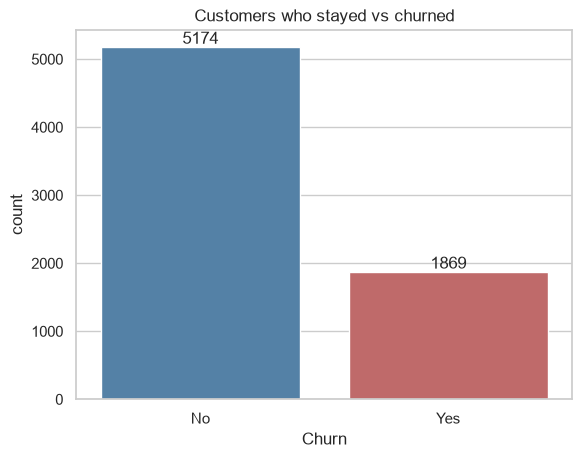

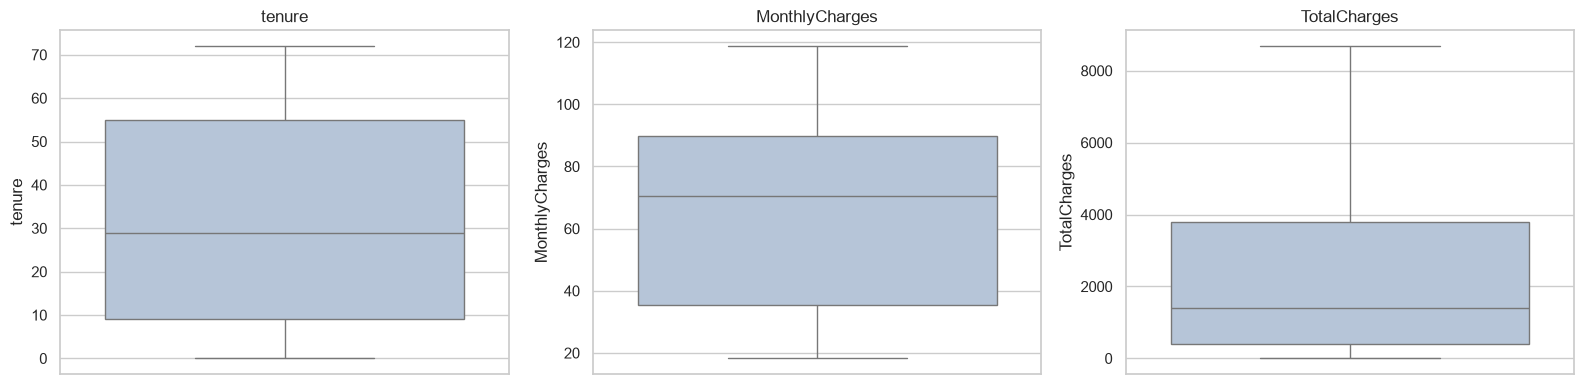

                 mean  count
Contract                    
Month-to-month  0.427   3875
One year        0.113   1473
Two year        0.028   1695

                  mean  count
InternetService              
Fiber optic      0.419   3096
DSL              0.190   2421
No               0.074   1526

                            mean  count
PaymentMethod                          
Electronic check           0.453   2365
Mailed check               0.191   1612
Bank transfer (automatic)  0.167   1544
Credit card (automatic)    0.152   1522



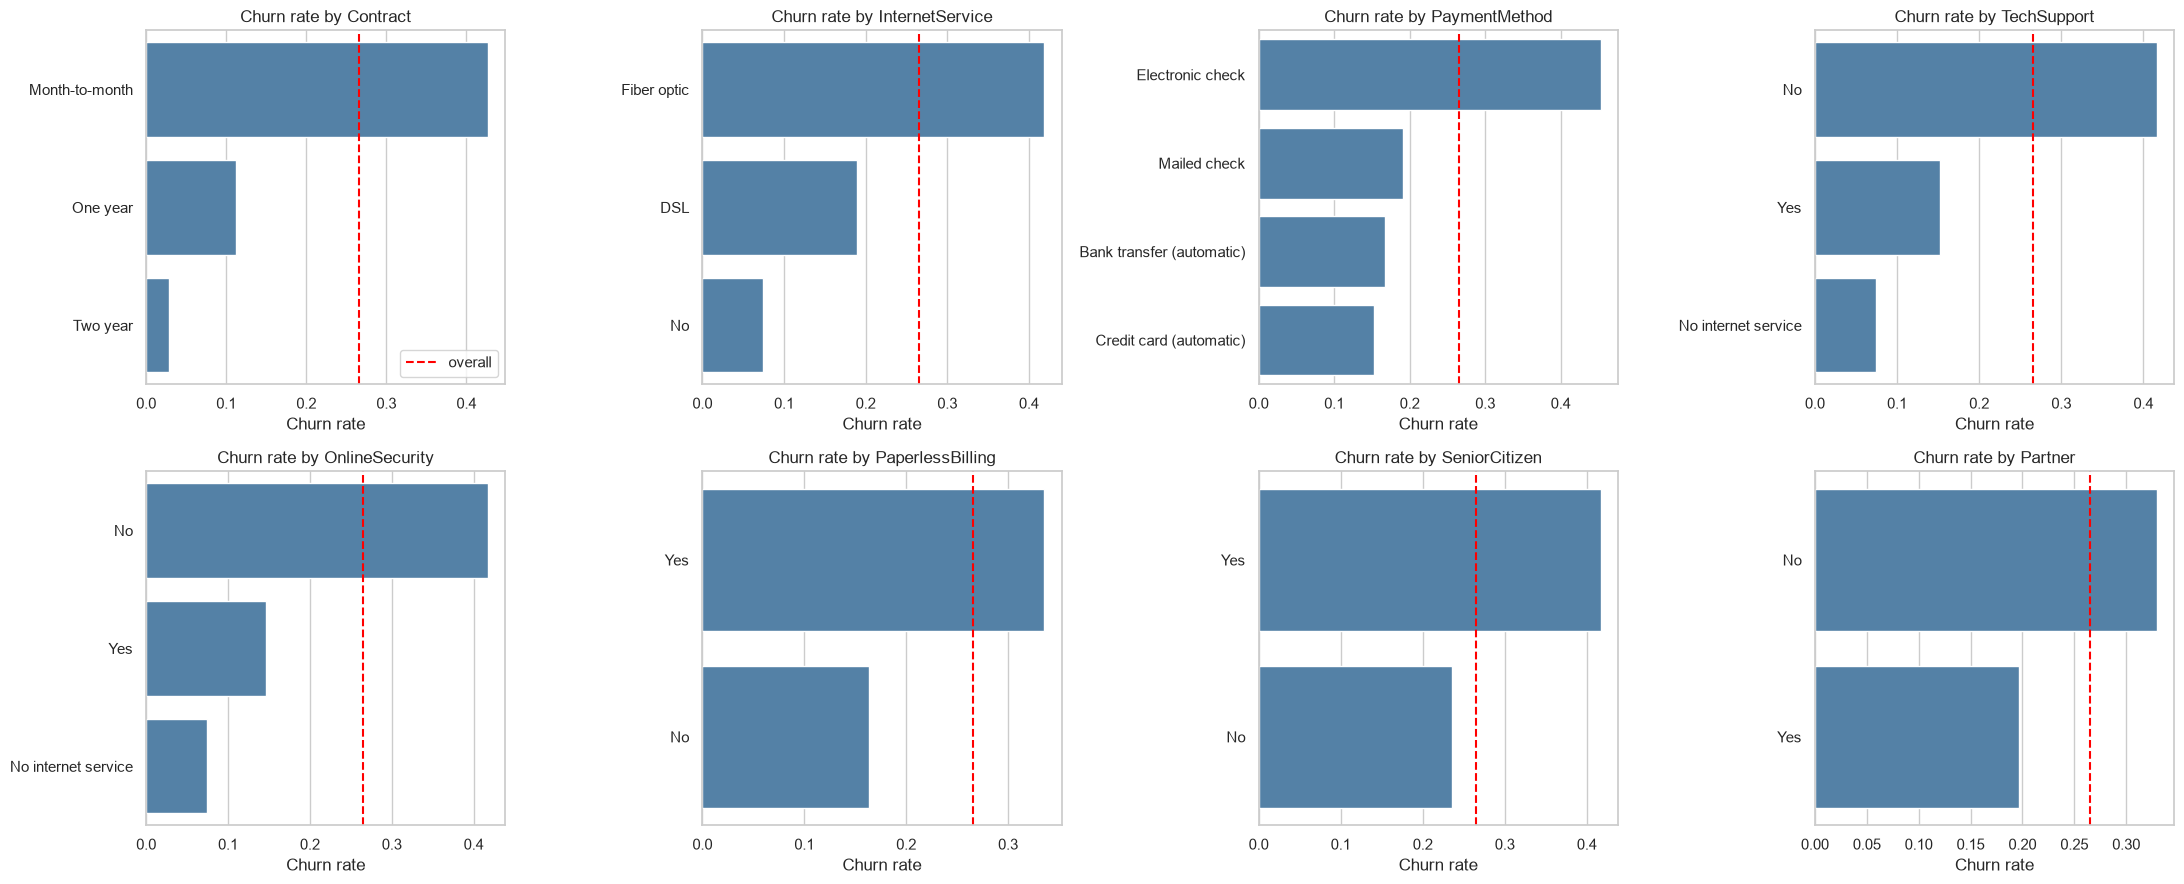

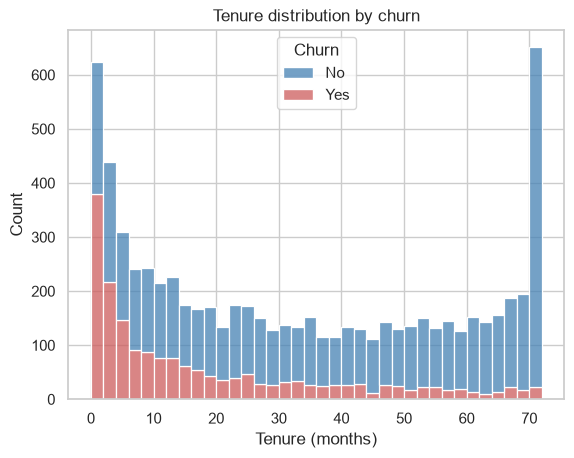

        count  mean   std  min   25%   50%   75%   max
Churn                                                 
No     5174.0  37.6  24.1  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  18.0  19.5  1.0   2.0  10.0  29.0  72.0


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9528\228508061.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["steelblue", "indianred"])


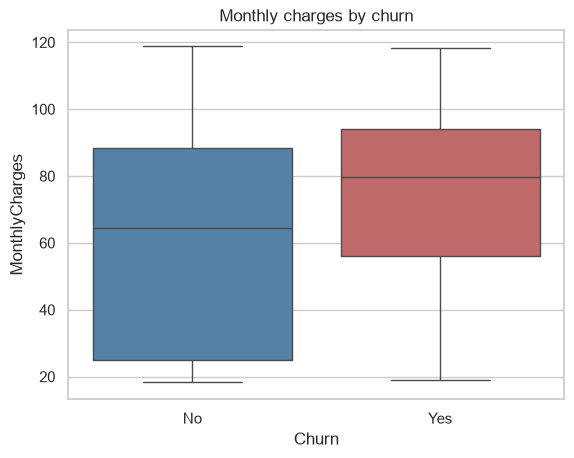

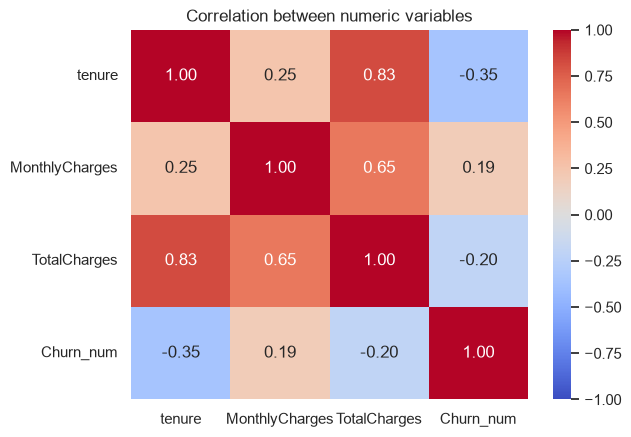

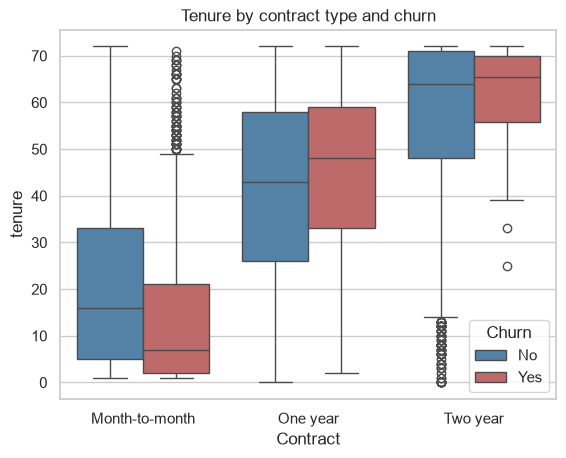

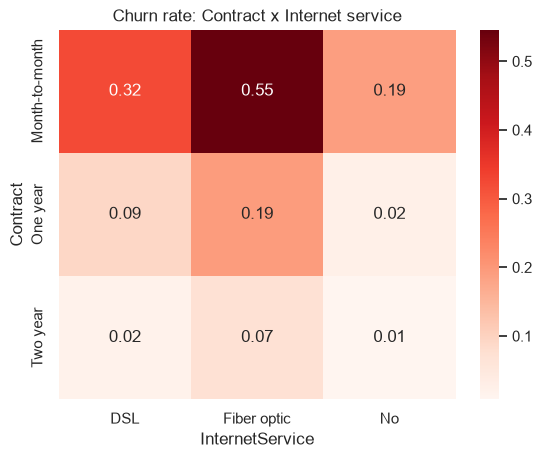

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Folder where we save charts for the README
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Churn rate overall:", round(df["Churn_num"].mean(), 3))
ax = sns.countplot(data=df, x="Churn", palette=["steelblue", "indianred"], order=["No", "Yes"])
for bar in ax.patches:
    ax.annotate(int(bar.get_height()), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")
plt.title("Customers who stayed vs churned")
plt.savefig(FIG_DIR / "01_churn_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df, y=col, ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_numeric_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(df.groupby(col)["Churn_num"].agg(["mean", "count"]).round(3).sort_values("mean", ascending=False))
    print()
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner"]

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
overall = df["Churn_num"].mean()

for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)["Churn_num"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="steelblue")
    ax.axvline(overall, color="red", linestyle="--", label="overall")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate")
    ax.set_ylabel("")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_churn_by_category.png", dpi=150, bbox_inches="tight")
plt.show()
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack",
             palette={"No": "steelblue", "Yes": "indianred"})
plt.title("Tenure distribution by churn")
plt.xlabel("Tenure (months)")
plt.savefig(FIG_DIR / "04_tenure_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()
print(df.groupby("Churn")["tenure"].describe().round(1))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["steelblue", "indianred"])
plt.title("Monthly charges by churn")
plt.savefig(FIG_DIR / "05_monthly_charges_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "Churn_num"]
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between numeric variables")
plt.savefig(FIG_DIR / "06_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
sns.boxplot(data=df, x="Contract", y="tenure", hue="Churn",
            palette={"No": "steelblue", "Yes": "indianred"})
plt.title("Tenure by contract type and churn")
plt.savefig(FIG_DIR / "07_contract_tenure.png", dpi=150, bbox_inches="tight")
plt.show()
pivot = df.pivot_table(index="Contract", columns="InternetService",
                       values="Churn_num", aggfunc="mean")
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Reds")
plt.title("Churn rate: Contract x Internet service")
plt.savefig(FIG_DIR / "08_contract_internet_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Data inspection and cleaning summary
- Dataset: 7,043 customers, 21 columns, no duplicates, customerID unique.
- Target: Churn, 26.5% Yes, 73.5% No (imbalanced).
- Hidden problem: TotalCharges was stored as text, with 11 blank values.
- All 11 have tenure = 0 (new customers, not billed yet), so I filled them with 0.
- Dropped customerID. Converted SeniorCitizen to Yes/No.
- No outliers removed: values are within realistic ranges.

## EDA key insights
1. **Class imbalance:** 26.5% of customers churned, so accuracy alone is misleading.
2. **Contract is the strongest signal:** month-to-month churn is ~43% versus ~3% for two-year contracts.
3. **New customers are most at risk:** churners have a median tenure of ~10 months versus ~38 for loyal customers.
4. **Fiber optic customers churn more (~42%)**, and the combination month-to-month + fiber is the riskiest segment (~54%).
5. **Payment method:** electronic-check users churn ~45%, automatic payment users ~15-17%.
6. **Support services matter:** customers without tech support or online security churn about 3x more.
7. **Caution:** these are associations, not proven causes.
8. **Outliers:** none removed; all values are realistic.

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,0.322,0.546,0.189
One year,0.093,0.193,0.025
Two year,0.019,0.072,0.008
